**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

*   NOMBRE: Diego Frías Guillén,
*   MATRÍCULA: A01841446,

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [2]:
cars_df = pd.read_csv('/content/automobile_dataset.csv')

cars_df.info()

columnas_numericas = cars_df.select_dtypes(include='number').shape[1]
columnas_texto = cars_df.select_dtypes(include='object').shape[1]

print('\nColumnas numéricas: ', columnas_numericas)
print('Columnas de texto: ', columnas_texto)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

### Respuesta Ejercicio 1

Inicialmente, el conjunto de datos contiene 12 columnas numéricas y 14 columnas de texto. Sin embargo, algunas variables numéricas fueron interpretadas como texto, debido a la presencia del símbolo "**?**".

In [3]:
columnas_con_interrogacion = cars_df.columns[
    cars_df.eq('?').any()
].tolist()

print('Columnas que contienen "?": ')

for columna in columnas_con_interrogacion:
    cantidad = cars_df[columna].eq('?').sum()
    print(f'{columna}: {cantidad}')

Columnas que contienen "?": 
normalized_losses: 41
bore: 4
stroke: 4
horsepower: 2
peak_rpm: 2


In [4]:
cars_df.replace('?', np.nan, inplace=True)

columnas_a_convertir = [
    'normalized_losses',
    'bore',
    'stroke',
    'horsepower',
    'peak_rpm'
]

cars_df[columnas_a_convertir] = cars_df[columnas_a_convertir].apply(
    pd.to_numeric

)

cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

### Respuesta Ejercicio 1

Se identificaron 5 columnas que contenían el símbolo "**?**": **normalized_losses**, **bore**, **stroke**, **horsepower** y **peak_rpm**. El símbolo se sustituyó por valores **NaN** y las columnas se convirtieron a tipo numérico. Después de la correción, el conjunto quedó conformado por 17 variables numéricas y 9 variables categóricas.

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

In [5]:
duplicados = cars_df.duplicated().sum()

porcentaje_faltantes = (
    cars_df.isna().mean()
    .mul(100)
    .round(2)
    .to_frame('porcentaje_faltantes')
)

print('Registros duplicados: ', duplicados)
display(porcentaje_faltantes)

Registros duplicados:  0


,porcentaje_faltantes
symboling,0.00
normalized_losses,20.00
make,0.00
fuel_type,0.00
aspiration,0.00
num_doors,0.00
body_style,0.00
drive_wheels,0.00
engine_location,0.00
wheel_base,0.00


In [6]:
variables_numericas = cars_df.select_dtypes(include='number').columns
variables_categoricas = cars_df.select_dtypes(include='object').columns

estadisticas_numericas = cars_df[variables_numericas].describe().T
estadisticas_numericas['asimetria'] = cars_df[variables_numericas].skew()
estadisticas_numericas['curtosis'] = cars_df[variables_numericas].kurtosis()

print('Estadísticas de las variables numéricas: ')
display(estadisticas_numericas)

Estadísticas de las variables numéricas: 


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00,0.211072,-0.676271
normalized_losses,164.0,122.000000,35.442168,65.00,94.00,115.00,150.00,256.00,0.765976,0.525440
wheel_base,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90,1.050214,1.017039
length,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10,0.155954,-0.082895
width,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30,0.904003,0.702764
height,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80,0.063123,-0.443812
curb_weight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00,0.681398,-0.042854
num_cylinders,205.0,4.380488,1.080854,2.00,4.00,4.00,4.00,12.00,2.817459,13.714866
engine_size,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00,1.947655,5.305682
bore,201.0,3.329751,0.273539,2.54,3.15,3.31,3.59,3.94,0.020016,-0.828945


In [7]:
print('Estadísticas de las variables categóricas: ')
display(cars_df[variables_categoricas].describe().T)

for columna in variables_categoricas:
    print(f'\n{columna}')

    frecuencias = (
        cars_df[columna]
        .value_counts(dropna=False)
        .to_frame('frecuencia')
    )

    display(frecuencias)

Estadísticas de las variables categóricas: 


,count,unique,top,freq
make,205,22,toyota,32
fuel_type,205,2,gas,185
aspiration,205,2,std,168
num_doors,205,2,four,116
body_style,205,5,sedan,96
drive_wheels,205,3,fwd,120
engine_location,205,2,front,202
engine_type,205,7,ohc,148
fuel_system,205,8,mpfi,94



make


,frecuencia
make,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
subaru,12
volkswagen,12
volvo,11
peugot,11



fuel_type


,frecuencia
fuel_type,
gas,185
diesel,20


... (10 outputs left out)


engine_type


,frecuencia
engine_type,
ohc,148
ohcf,15
ohcv,13
dohc,12
l,12
rotor,4
dohcv,1



fuel_system


,frecuencia
fuel_system,
mpfi,94
2bbl,66
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


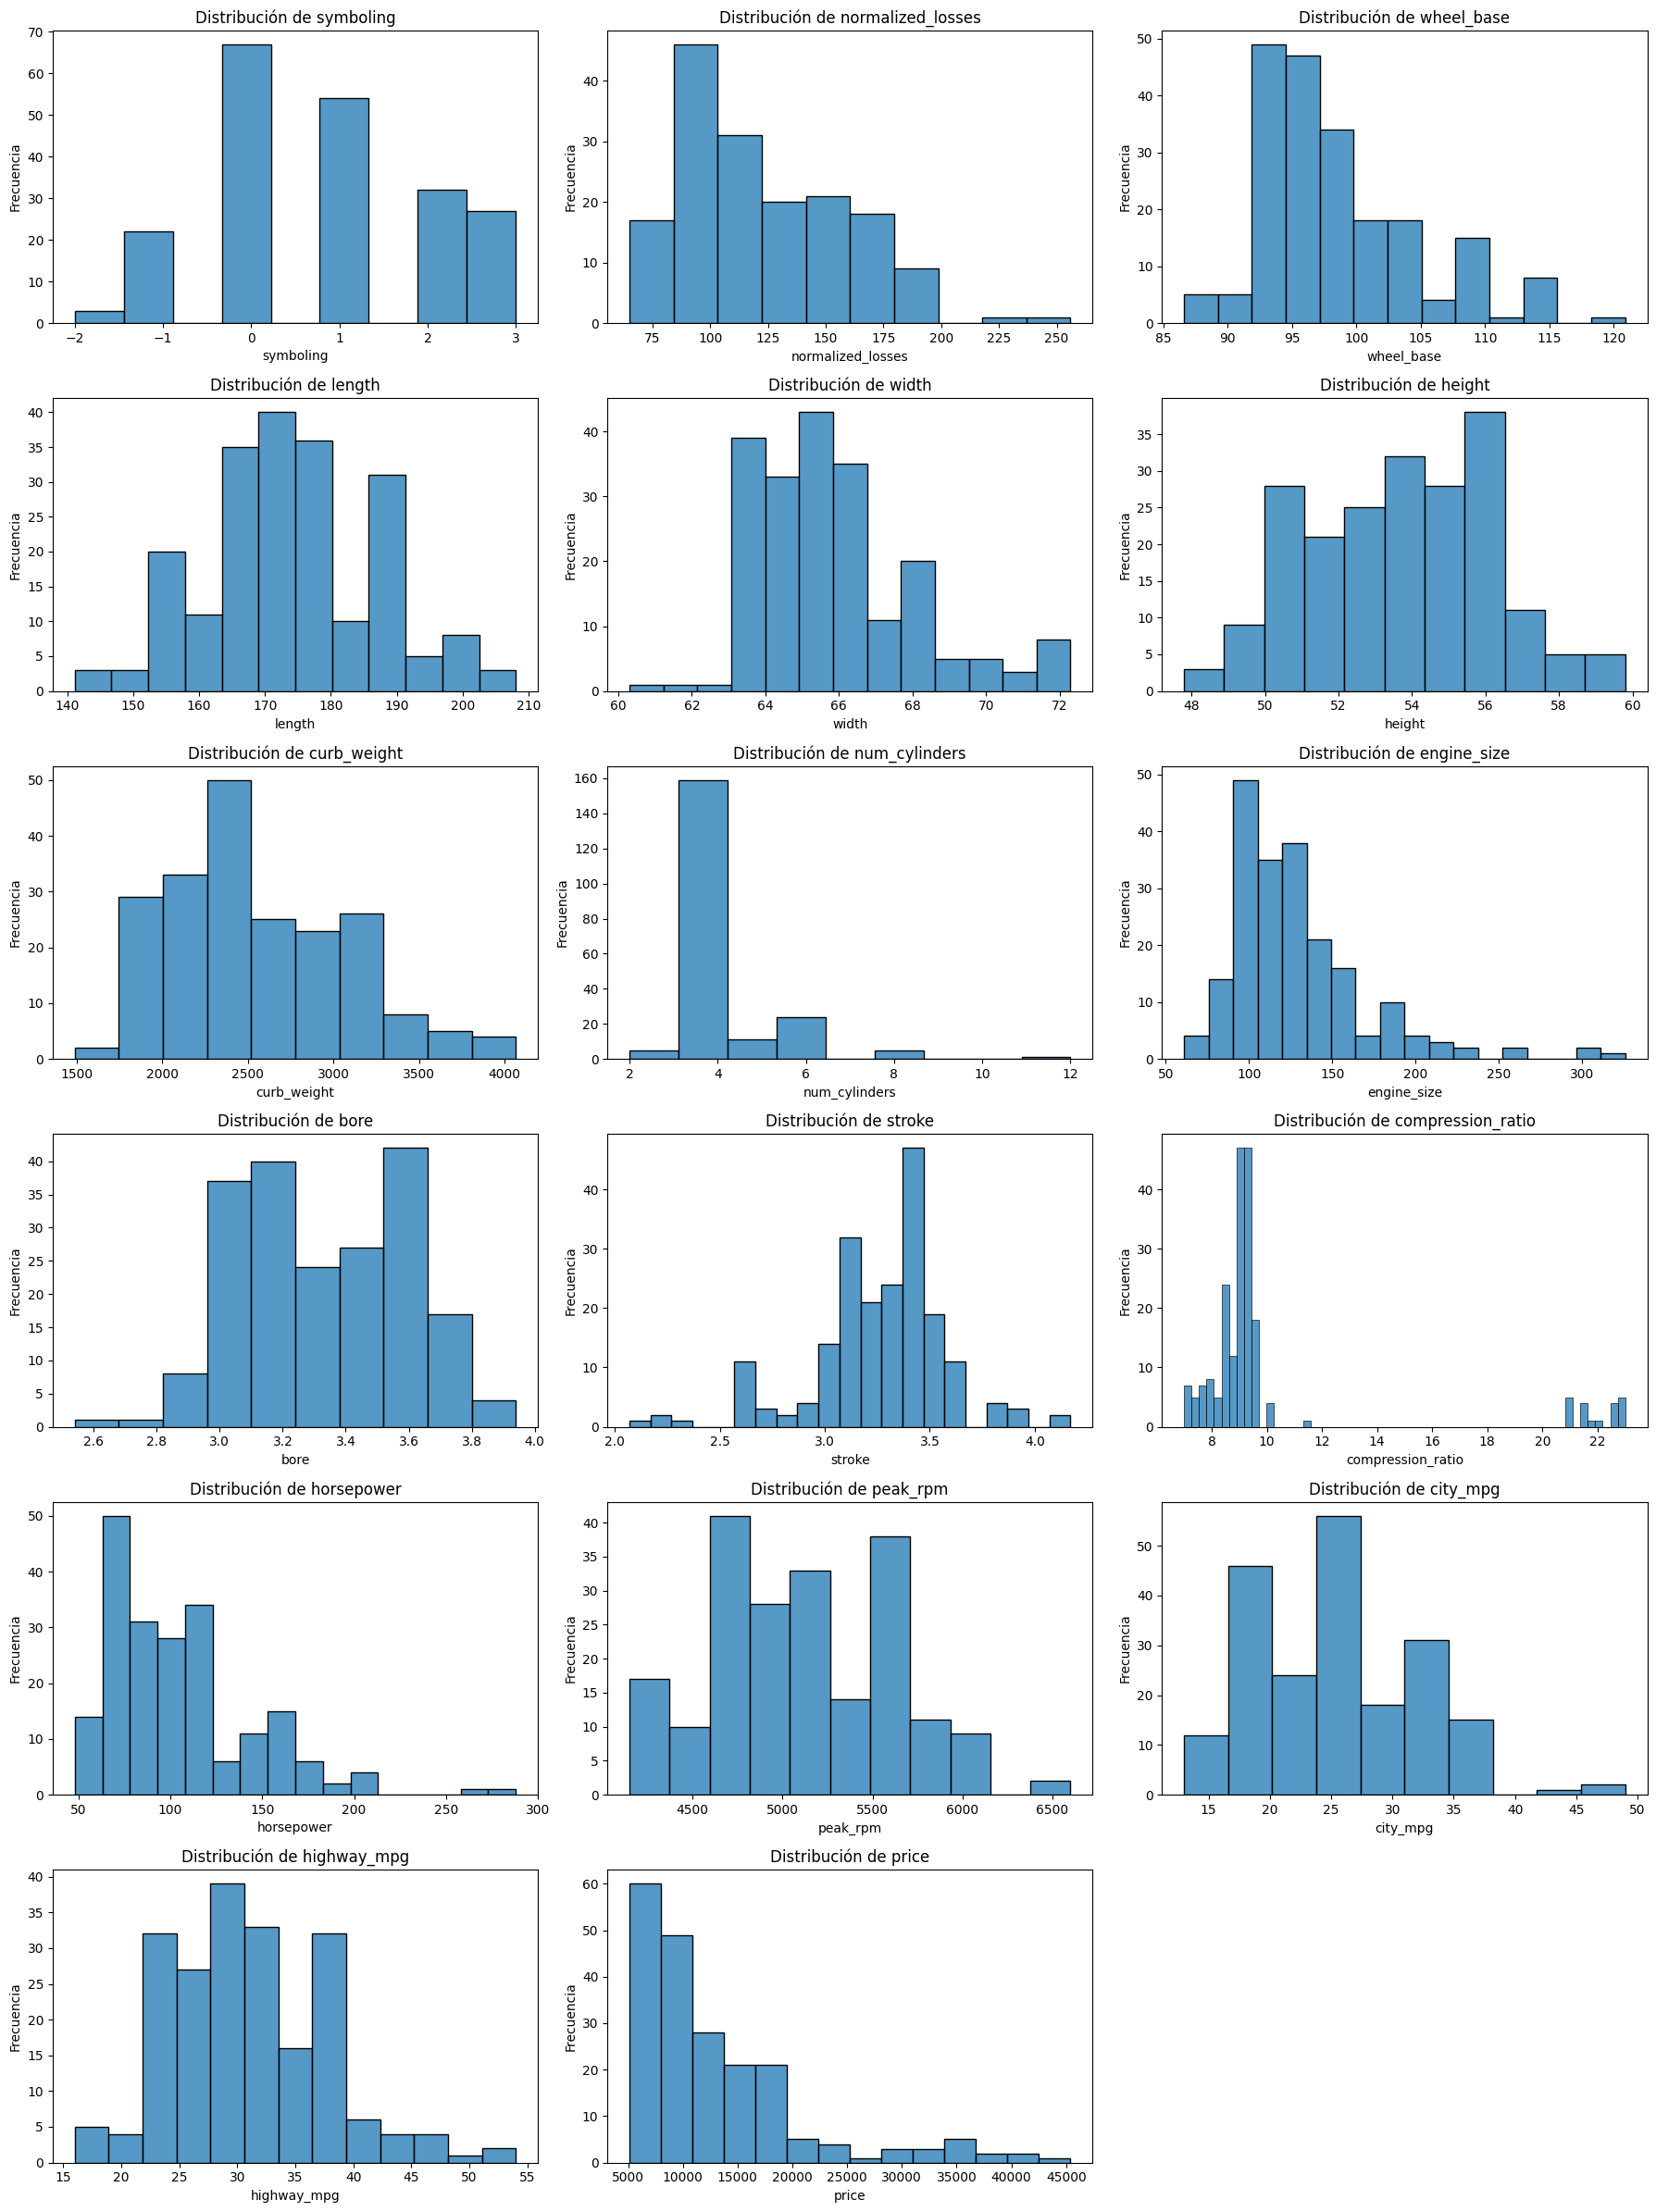

In [8]:
filas = int(np.ceil(len(variables_numericas) /3))

fig, axes = plt.subplots(filas, 3, figsize=(18, filas * 4))
axes = axes.flatten()

for ax, columna in zip(axes, variables_numericas):
  sns.histplot(data=cars_df, x=columna, ax=ax)
  ax.set_title(f'Distribución de {columna}')
  ax.set_xlabel(columna)
  ax.set_ylabel('Frecuencia')

for ax in axes[len(variables_numericas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

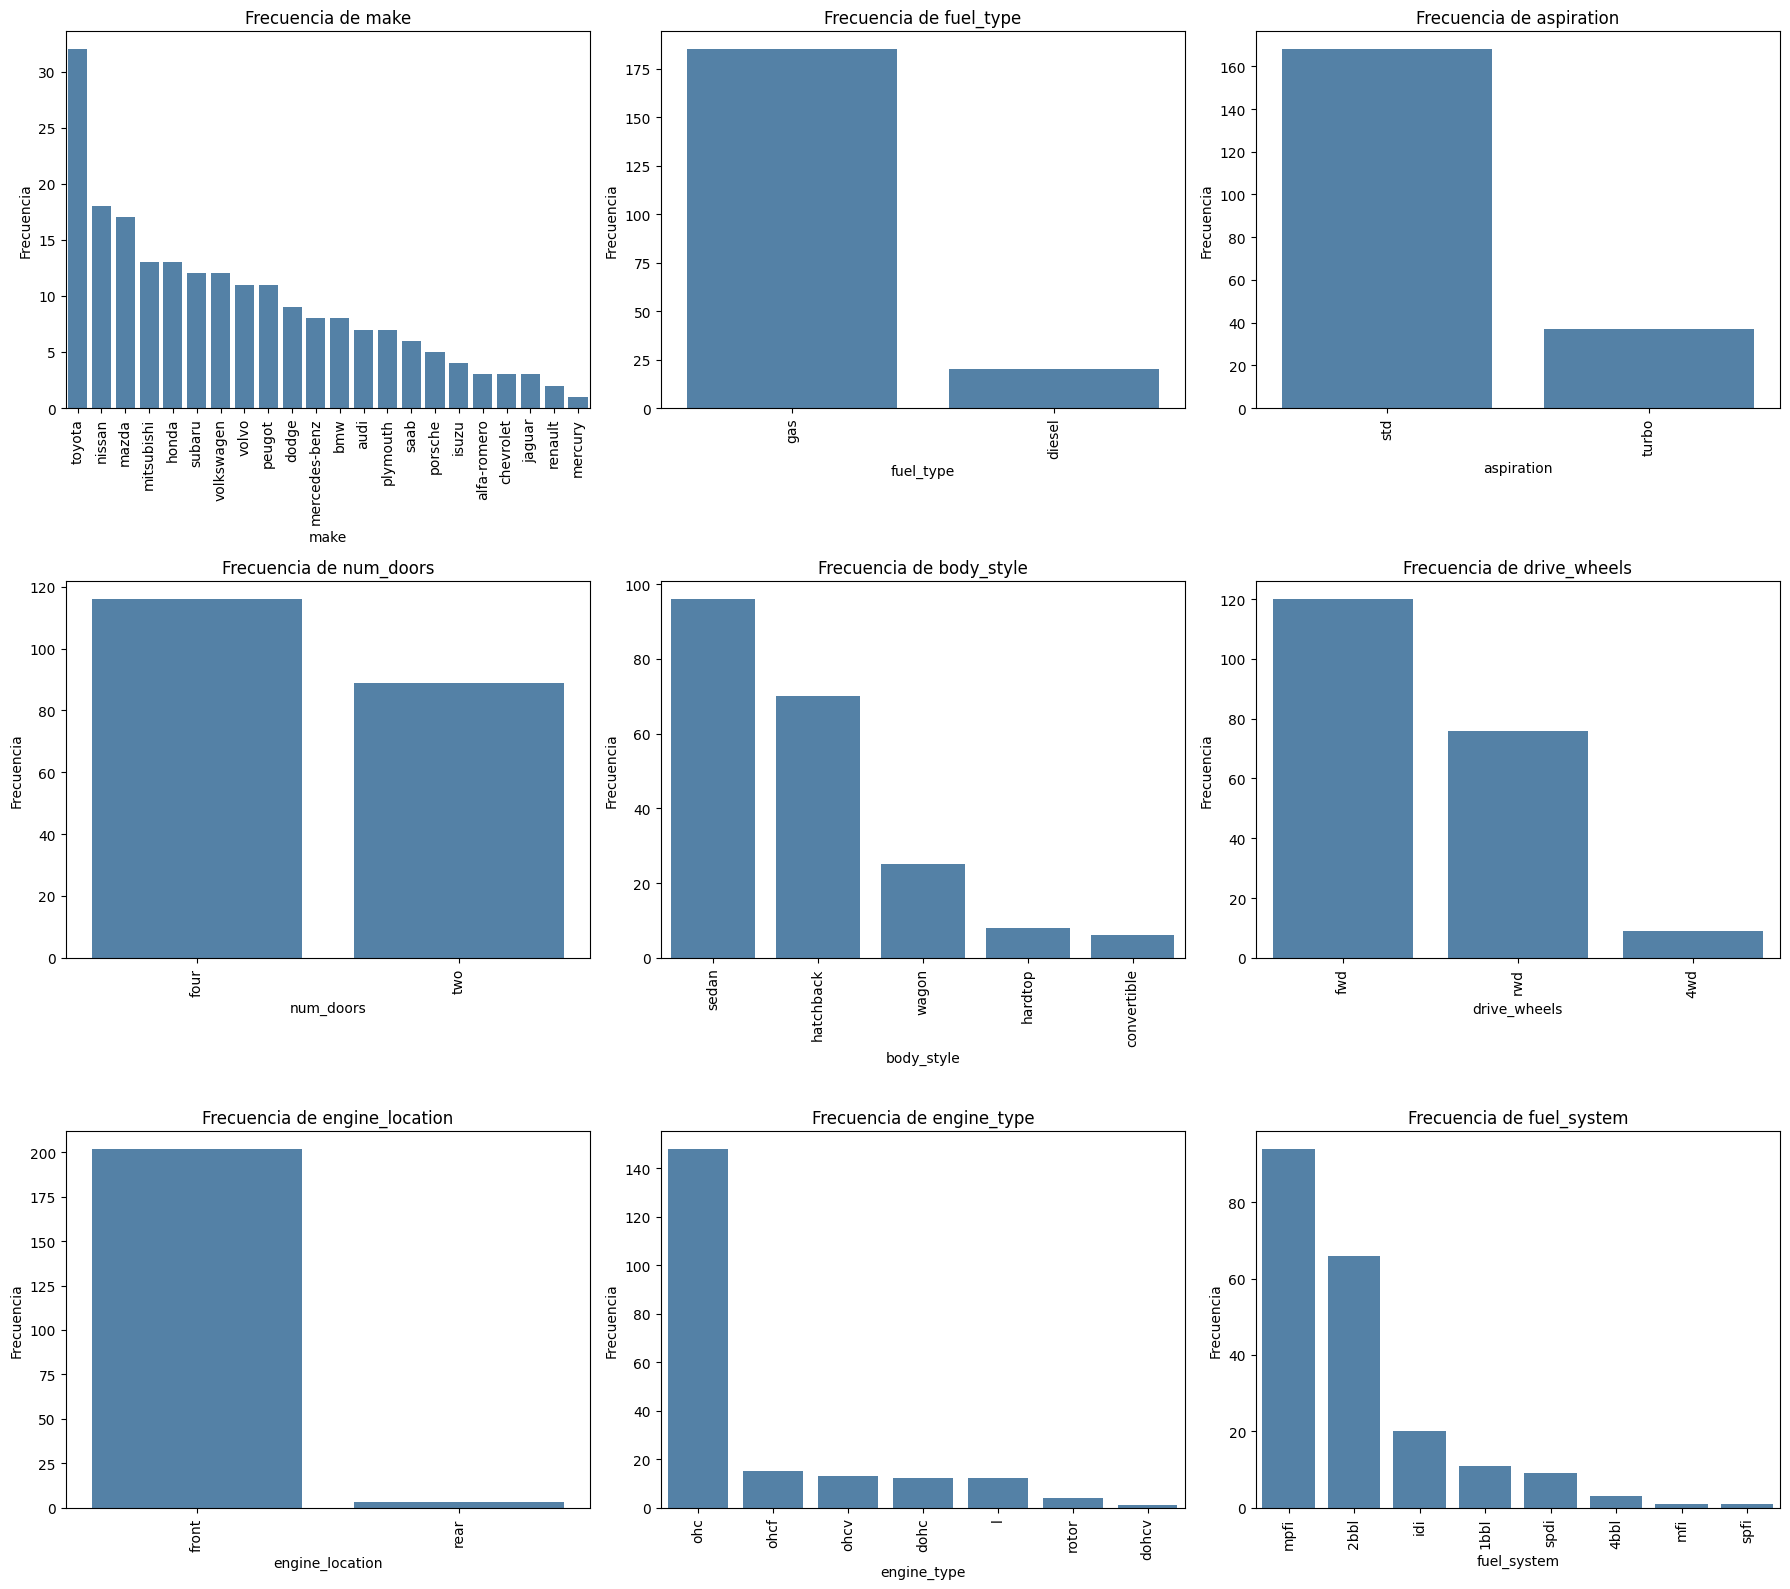

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
axes = axes.flatten()

for ax, columna in zip(axes, variables_categoricas):
    orden = cars_df[columna].value_counts().index

    sns.countplot(
        data=cars_df,
        x=columna,
        order=orden,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(f'Frecuencia de {columna}')
    ax.set_xlabel(columna)
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

### Respuesta Ejercicio 2

El análisis univariado muestra que variables, como **engine_size**, **compression_ratio**, **horsepower** y **price**, presentan asimetría positiva, lo que indica la existencia de algunos vehículos con valores considerablemente elevados. En las variables categóricas predominan los automóviles de gasolina, aspiración estándar, 4 puertas, carrocería sedán, tracción delantera y motor ubicado al frente.

# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

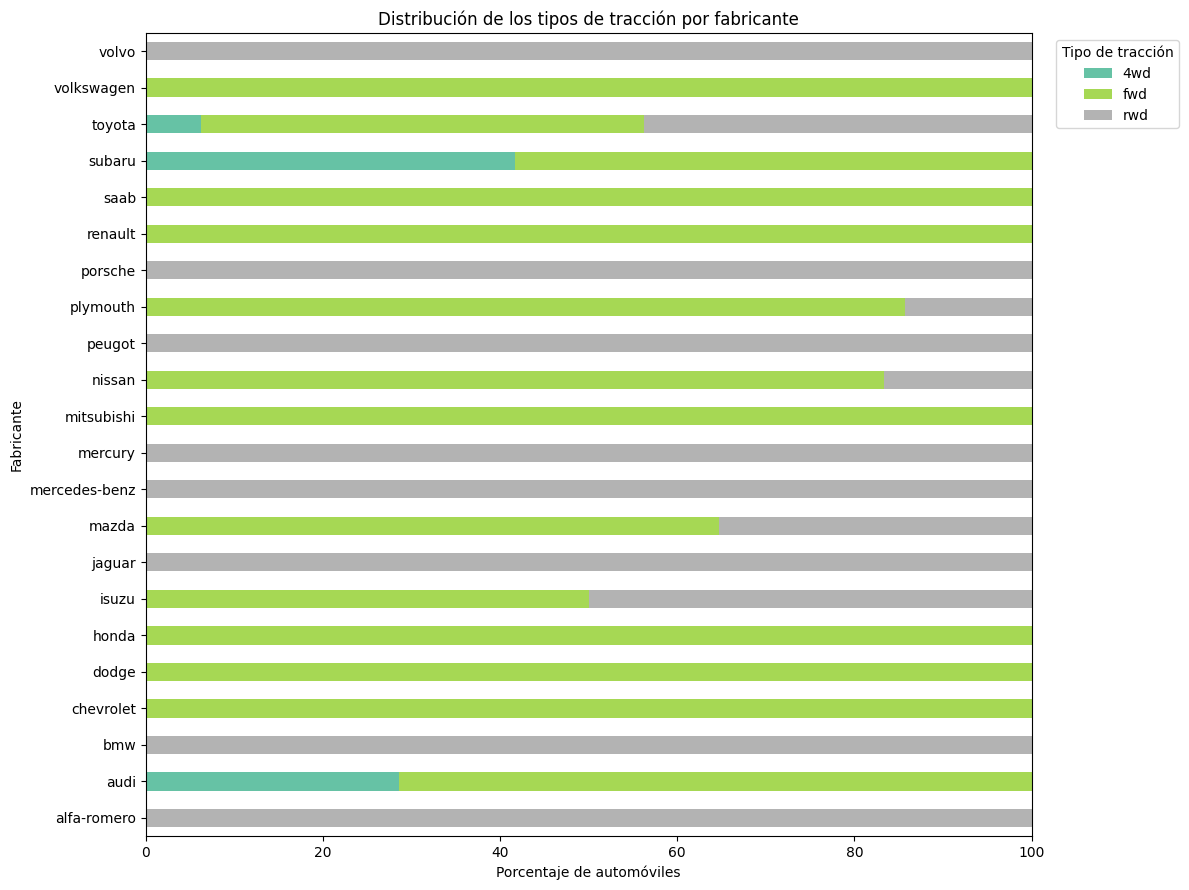

In [10]:
distribucion_traccion = pd.crosstab(
    cars_df['make'],
    cars_df['drive_wheels'],
    normalize='index'
).mul(100)

distribucion_traccion.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 9),
    colormap='Set2'
)

plt.title('Distribución de los tipos de tracción por fabricante')
plt.xlabel('Porcentaje de automóviles')
plt.ylabel('Fabricante')
plt.xlim(0, 100)
plt.legend(title='Tipo de tracción', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Respuesta Ejercicio 3

La distribución de la tracción varía según el fabricante. Algunas marcas, como Chevrolet, Dodge, Honda, Mitsubishi y Volkswagen, se concentran en la tracción delantera; mientras que BMW, Jaguar, Mercedes-Benz, Porsche y Volvo utilizan principalmente tracción trasera. La tracción en las 4 ruedas es la menos frecuente y aparece principalmente en Audi, Subaru y Toyota.

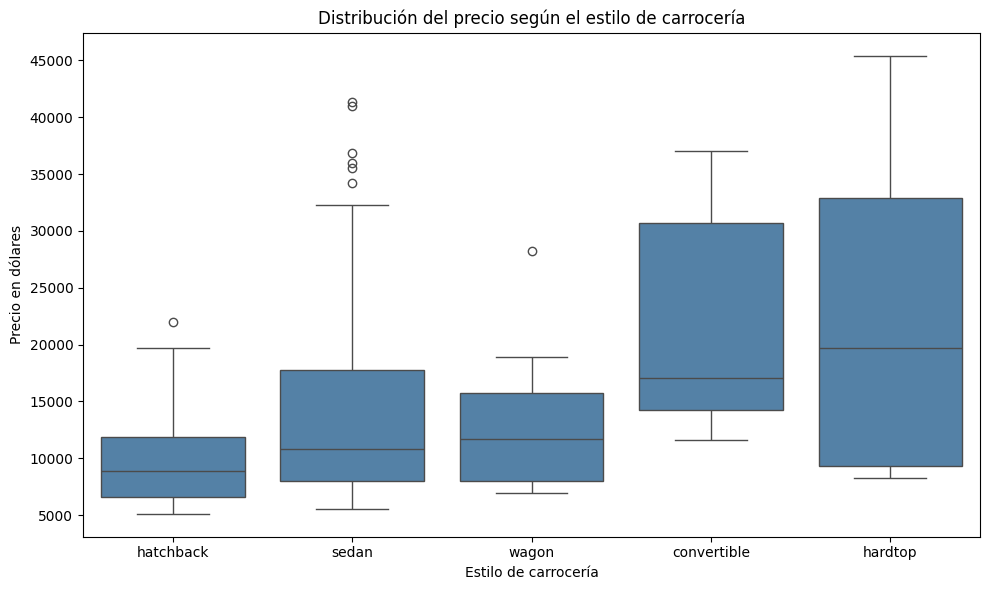

In [11]:
orden_carrocerias = (
    cars_df.groupby('body_style')['price']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(10,6))

sns.boxplot(
    data=cars_df,
    x='body_style',
    y='price',
    order=orden_carrocerias,
    color='steelblue'
)

plt.title('Distribución del precio según el estilo de carrocería')
plt.xlabel('Estilo de carrocería')
plt.ylabel('Precio en dólares')
plt.tight_layout()
plt.show()

### Respuesta Ejercicio 3

Los automóviles de tipo **hardtop** presentan la mediana de precio más alta, seguidos por los convertibles. En contraste, los vehículos **hatchback** tienen la mediana más baja. Los sedantes muestran una dispersión amplia y varios precios elevados, lo que indica que esta categoría incluye tanto modelos económicos como vehículos de gama alta.

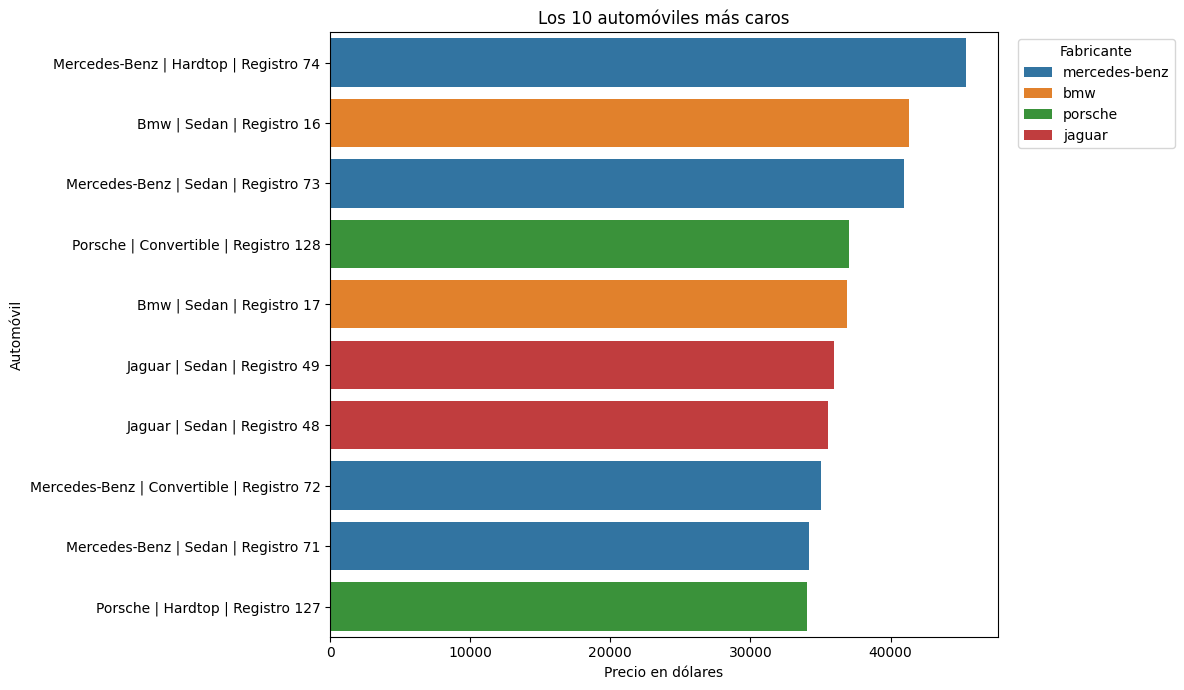

In [12]:
autos_mas_caros = cars_df.nlargest(10, 'price').copy()

autos_mas_caros['automovil'] = (
    autos_mas_caros['make'].str.title()
    + ' | '
    + autos_mas_caros['body_style'].str.title()
    + ' | Registro '
    + autos_mas_caros.index.astype(str)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=autos_mas_caros,
    x='price',
    y='automovil',
    hue='make',
    order=autos_mas_caros['automovil'],
    dodge=False,
    palette='tab10'
)

plt.title('Los 10 automóviles más caros')
plt.xlabel('Precio en dólares')
plt.ylabel('Automóvil')
plt.legend(title='Fabricante', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Respuesta Ejercicio 3

El automóvil más caro del conjunto es un **hardtop** de Mercedes-Benz, con un precio de 45,400 dólares. Mercedes-Benz concentra 4 de los 10 vehículos más costosos, mientras que BMW, Jaguar y Porsche tienen 2 registros cada uno. Esto indica que los precios más elevados se concentran en un grupo reducido de fabricantes asociados con vehículos de gama alta.

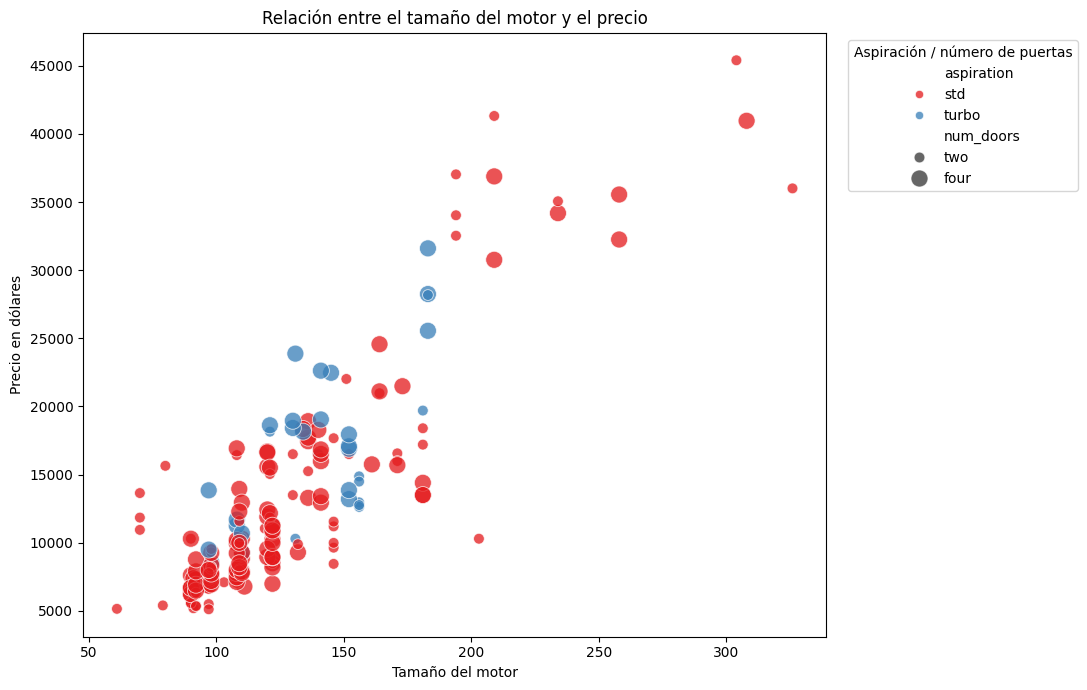

In [13]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=cars_df,
    x='engine_size',
    y='price',
    hue='aspiration',
    size='num_doors',
    sizes={'two': 60, 'four': 150},
    alpha=0.75,
    palette='Set1'
)

plt.title('Relación entre el tamaño del motor y el precio')
plt.xlabel('Tamaño del motor')
plt.ylabel('Precio en dólares')
plt.legend(
    title='Aspiración / número de puertas',
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

### Respuesta Ejercicio 3

Se observa una relación positiva clara entre el tamaño del motor y el precio: conforme aumenta **engine_size**, los automóviles tienden a ser más costosos. La correlación entre ambas variables es aproximadamente 0.86, lo que indica una asociación más fuerte. Además, los vehículos con aspiración turbo presentan generalmente precios más altos, aunque existe superposición con los modelos de aspiración estándar. El tamaño de los puntos permite distinguir los automóviles de 2 y 4 puertas sin modificar la tendencia principal.

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---